In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_raw_data
from src.data_cleaning import clean_data
from src.feature_engineering import create_features

# Load dataset
data = load_raw_data()

# Clean dataset
data = clean_data(data)

# Create engineered features
data = create_features(data)

print("Dataset Shape:", data.shape)

Dataset Shape: (48696, 42)


In [2]:
# Input features
X = data.drop(
    columns=[
        "mileage_kmpl",
        "record_id",
        "speed_band"
    ],
    errors="ignore"
)

# Target
y = data["mileage_kmpl"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeatures used for training:")
print(X.columns.tolist())

Input Features Shape: (48696, 39)
Target Shape: (48696,)

Features used for training:
['brand', 'model', 'segment', 'engine_cc', 'max_power_bhp', 'kerb_weight_kg', 'fuel_tank_l', 'transmission', 'gears', 'cooling', 'abs_type', 'model_year', 'odometer_km', 'months_since_service', 'tyre_type', 'tyre_condition', 'tyre_pressure_front_psi', 'tyre_pressure_rear_psi', 'time_of_day', 'road_type', 'road_surface', 'surface_condition', 'weather', 'traffic_density', 'stops_per_km', 'gradient_pct', 'avg_speed_kmph', 'max_speed_kmph', 'riding_style', 'rider_weight_kg', 'pillion', 'luggage_kg', 'fuel_type', 'trip_distance_km', 'power_to_weight_ratio', 'engine_cc_per_kg', 'average_tyre_pressure', 'tyre_pressure_difference', 'speed_difference']


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Targets:", y_train.shape)
print("Testing Targets:", y_test.shape)

Training Data: (38956, 39)
Testing Data: (9740, 39)
Training Targets: (38956,)
Testing Targets: (9740,)


In [4]:
# Check numerical columns
numerical_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Check categorical columns
categorical_columns = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical Features:", len(numerical_columns))
print(numerical_columns)

print("\nCategorical Features:", len(categorical_columns))
print(categorical_columns)

Numerical Features: 23
['engine_cc', 'max_power_bhp', 'kerb_weight_kg', 'fuel_tank_l', 'gears', 'model_year', 'odometer_km', 'months_since_service', 'tyre_pressure_front_psi', 'tyre_pressure_rear_psi', 'stops_per_km', 'gradient_pct', 'avg_speed_kmph', 'max_speed_kmph', 'rider_weight_kg', 'pillion', 'luggage_kg', 'trip_distance_km', 'power_to_weight_ratio', 'engine_cc_per_kg', 'average_tyre_pressure', 'tyre_pressure_difference', 'speed_difference']

Categorical Features: 16
['brand', 'model', 'segment', 'transmission', 'cooling', 'abs_type', 'tyre_type', 'tyre_condition', 'time_of_day', 'road_type', 'road_surface', 'surface_condition', 'weather', 'traffic_density', 'riding_style', 'fuel_type']


In [ ]:
# Import preprocessing function
from src.preprocessing import build_preprocessor

# Create preprocessing pipeline
preprocessor = build_preprocessor(X_train)

# Learn preprocessing rules from training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same rules to testing data
X_test_processed = preprocessor.transform(X_test)

# Check results
print("Training Data Before:", X_train.shape)
print("Training Data After:", X_train_processed.shape)

print("\nTesting Data Before:", X_test.shape)
print("Testing Data After:", X_test_processed.shape)

Training Data Before: (38956, 39)
Training Data After: (38956, 259)

Testing Data Before: (9740, 39)
Testing Data After: (9740, 259)


In [6]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
model.fit(
    X_train_processed,
    y_train
)

print("Model training completed!")

Model training completed!


In [7]:
import pandas as pd
# Make predictions using testing data
y_pred = model.predict(X_test_processed)

# Display actual and predicted mileage
results = pd.DataFrame({
    "Actual Mileage": y_test.values,
    "Predicted Mileage": y_pred
})

print(results.head(10))

   Actual Mileage  Predicted Mileage
0            9.39             8.1837
1            7.39             6.8042
2           30.20            30.7610
3           19.98            22.1442
4           14.90            14.5879
5           12.20            11.2142
6           23.32            25.0677
7           29.63            29.0162
8           27.96            27.7284
9           16.46            18.1917


In [9]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)


# Display results
print("MODEL EVALUATION")
print("------------------------")

print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

MODEL EVALUATION
------------------------
MAE: 1.6955
MSE: 5.5942
RMSE: 2.3652
R2 Score: 0.9542


In [10]:
# Predict on training data
train_predictions = model.predict(X_train_processed)

# Predict on testing data
test_predictions = model.predict(X_test_processed)

# Calculate R2 scores
train_r2 = r2_score(y_train, train_predictions)
test_r2 = r2_score(y_test, test_predictions)

print("TRAINING R2:", round(train_r2, 4))
print("TESTING R2:", round(test_r2, 4))

TRAINING R2: 0.9935
TESTING R2: 0.9542


In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create baseline model
baseline_model = DummyRegressor(strategy="mean")

# Train baseline model
baseline_model.fit(X_train, y_train)

# Make predictions
baseline_predictions = baseline_model.predict(X_test)

# Evaluate baseline
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_mse = mean_squared_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, baseline_predictions)

print("BASELINE MODEL EVALUATION")
print("-------------------------")
print("MAE:", round(baseline_mae, 4))
print("MSE:", round(baseline_mse, 4))
print("RMSE:", round(baseline_rmse, 4))
print("R2 Score:", round(baseline_r2, 4))

BASELINE MODEL EVALUATION
-------------------------
MAE: 8.8695
MSE: 122.1711
RMSE: 11.0531
R2 Score: -0.0001


In [12]:
import pandas as pd

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get feature importance scores
importance_scores = model.feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 20 features
print("TOP 20 IMPORTANT FEATURES")
print("-------------------------")
print(feature_importance.head(20))

TOP 20 IMPORTANT FEATURES
-------------------------
                                    Feature  Importance
12                numerical__avg_speed_kmph    0.369989
1                  numerical__max_power_bhp    0.219958
2                 numerical__kerb_weight_kg    0.183413
190           categorical__segment_Commuter    0.050638
19              numerical__engine_cc_per_kg    0.033684
252    categorical__riding_style_aggressive    0.024925
0                      numerical__engine_cc    0.017333
11                  numerical__gradient_pct    0.015731
6                    numerical__odometer_km    0.010608
18         numerical__power_to_weight_ratio    0.006899
5                     numerical__model_year    0.005160
238  categorical__surface_condition_flooded    0.004110
198     categorical__segment_Sport Commuter    0.004023
10                  numerical__stops_per_km    0.003284
14               numerical__rider_weight_kg    0.002844
7           numerical__months_since_service    0.002

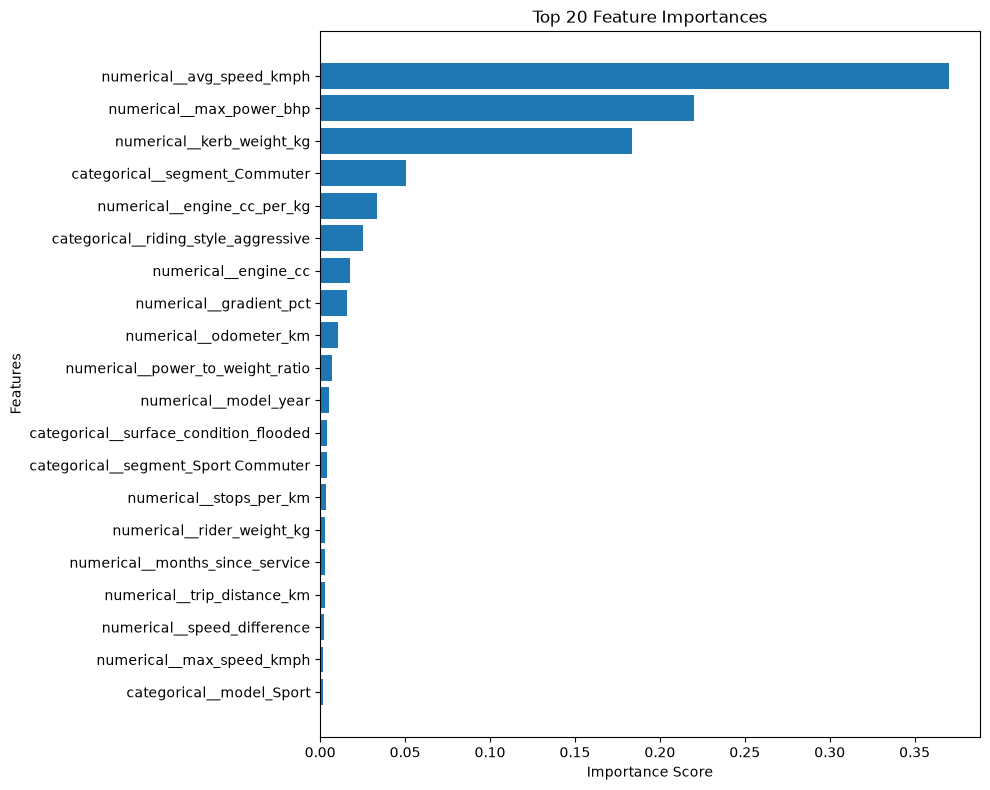

In [13]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(20)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 20 Feature Importances")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import numpy as np
import pandas as pd


# Create different models
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}


# Store evaluation results
model_results = []


# Train and evaluate each model
for model_name, current_model in models.items():

    print("Training:", model_name)

    current_model.fit(X_train_processed, y_train)

    predictions = current_model.predict(X_test_processed)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    model_results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })


# Create comparison table
comparison = pd.DataFrame(model_results)

comparison = comparison.sort_values(
    by="R2 Score",
    ascending=False
)


# Display results
print("\nMODEL COMPARISON")
print("----------------")
print(comparison.round(4).to_string(index=False))

Training: Linear Regression
Training: Decision Tree
Training: Random Forest
Training: Gradient Boosting

MODEL COMPARISON
----------------
            Model    MAE     MSE   RMSE  R2 Score
    Random Forest 1.6955  5.5942 2.3652    0.9542
Gradient Boosting 1.8077  6.2951 2.5090    0.9485
    Decision Tree 2.5520 12.6582 3.5578    0.8964
Linear Regression 3.0166 15.2753 3.9084    0.8750


In [15]:
# Compare training and testing performance
generalization_results = []

for model_name, current_model in models.items():

    # Predictions on training data
    train_predictions = current_model.predict(X_train_processed)

    # Predictions on testing data
    test_predictions = current_model.predict(X_test_processed)

    # Calculate R2 scores
    train_r2 = r2_score(y_train, train_predictions)
    test_r2 = r2_score(y_test, test_predictions)

    generalization_results.append({
        "Model": model_name,
        "Training R2": train_r2,
        "Testing R2": test_r2,
        "R2 Difference": train_r2 - test_r2
    })

# Display results
generalization = pd.DataFrame(generalization_results)

print("GENERALIZATION COMPARISON")
print("-------------------------")
print(generalization.round(4).to_string(index=False))

GENERALIZATION COMPARISON
-------------------------
            Model  Training R2  Testing R2  R2 Difference
Linear Regression       0.8776      0.8750         0.0026
    Decision Tree       1.0000      0.8964         0.1036
    Random Forest       0.9935      0.9542         0.0393
Gradient Boosting       0.9511      0.9485         0.0027


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Create Random Forest pipeline
rf_pipeline = Pipeline([
    ("preprocessor", build_preprocessor(X_train)),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

# Random Forest hyperparameters
rf_parameters = {
    "model__n_estimators": [100, 150, 200],
    "model__max_depth": [None, 15, 25],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.7, 1.0]
}

# Search for the best Random Forest configuration
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_parameters,
    n_iter=6,
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Tuning Random Forest...")
rf_search.fit(X_train, y_train)

print("\nBEST RANDOM FOREST PARAMETERS:")
print(rf_search.best_params_)

print("Best Cross-Validation RMSE:", round(-rf_search.best_score_, 4))


# Create Gradient Boosting pipeline
gb_pipeline = Pipeline([
    ("preprocessor", build_preprocessor(X_train)),
    ("model", GradientBoostingRegressor(
        random_state=42
    ))
])

# Gradient Boosting hyperparameters
gb_parameters = {
    "model__n_estimators": [100, 150, 200],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__min_samples_leaf": [1, 2, 4],
    "model__subsample": [0.8, 1.0]
}

# Search for the best Gradient Boosting configuration
gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_parameters,
    n_iter=6,
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("\nTuning Gradient Boosting...")
gb_search.fit(X_train, y_train)

print("\nBEST GRADIENT BOOSTING PARAMETERS:")
print(gb_search.best_params_)

print("Best Cross-Validation RMSE:", round(-gb_search.best_score_, 4))

Tuning Random Forest...
Fitting 3 folds for each of 6 candidates, totalling 18 fits

BEST RANDOM FOREST PARAMETERS:
{'model__n_estimators': 150, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': 25}
Best Cross-Validation RMSE: 2.4437

Tuning Gradient Boosting...
Fitting 3 folds for each of 6 candidates, totalling 18 fits

BEST GRADIENT BOOSTING PARAMETERS:
{'model__subsample': 0.8, 'model__n_estimators': 150, 'model__min_samples_leaf': 4, 'model__max_depth': 4, 'model__learning_rate': 0.1}
Best Cross-Validation RMSE: 2.0876


In [15]:

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd

# Create tuned Random Forest pipeline
tuned_rf = Pipeline([
    ("preprocessor", build_preprocessor(X_train)),
    ("model", RandomForestRegressor(
        n_estimators=150,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features=0.7,
        max_depth=25,
        random_state=42,
        n_jobs=-1
    ))
])

# Create tuned Gradient Boosting pipeline
tuned_gb = Pipeline([
    ("preprocessor", build_preprocessor(X_train)),
    ("model", GradientBoostingRegressor(
        subsample=0.8,
        n_estimators=150,
        min_samples_leaf=4,
        max_depth=4,
        learning_rate=0.1,
        random_state=42
    ))
])

# Train both tuned models
tuned_rf.fit(X_train, y_train)
tuned_gb.fit(X_train, y_train)

# Store models
tuned_models = {
    "Tuned Random Forest": tuned_rf,
    "Tuned Gradient Boosting": tuned_gb
}

# Evaluate models
tuned_results = []

for model_name, model in tuned_models.items():

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    tuned_results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Display comparison
tuned_comparison = pd.DataFrame(tuned_results)

tuned_comparison = tuned_comparison.sort_values(
    by="RMSE",
    ascending=True
)

print("\nTUNED MODEL TEST RESULTS")
print("------------------------")
print(tuned_comparison.round(4).to_string(index=False))



TUNED MODEL TEST RESULTS
------------------------
                  Model    MAE    MSE   RMSE  R2 Score
Tuned Gradient Boosting 1.4692 4.2543 2.0626    0.9652
    Tuned Random Forest 1.6718 5.4586 2.3364    0.9553


In [18]:

import joblib
from pathlib import Path

# Define artifacts directory
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"

# Create directory if it doesn't exist
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# Save the best tuned model
model_path = ARTIFACTS_DIR / "gradient_boosting_model.joblib"

joblib.dump(tuned_gb, model_path)

print("Model saved successfully!")
print("Location:", model_path)


Model saved successfully!
Location: c:\Users\tipst\OneDrive\Desktop\Bike Mileage Model\artifacts\gradient_boosting_model.joblib


In [ ]:

import joblib
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from src.data_loader import load_raw_data
from src.data_cleaning import clean_data
from src.feature_engineering import create_features
from src.preprocessing import build_preprocessor

import numpy as np

# 1. Load and clean original data
raw_data = load_raw_data()
raw_data = clean_data(raw_data)

# 2. Separate raw features and target
X_raw = raw_data.drop(
    columns=["mileage_kmpl", "record_id", "speed_band"],
    errors="ignore"
)

y_final = raw_data["mileage_kmpl"]

# 3. Split raw data
X_train_raw, X_test_raw, y_train_final, y_test_final = train_test_split(
    X_raw,
    y_final,
    test_size=0.2,
    random_state=42
)

# 4. Create engineered training features for preprocessing setup
X_train_engineered = create_features(X_train_raw)

preprocessor = build_preprocessor(X_train_engineered)

# 5. Build the complete pipeline
final_pipeline = Pipeline([
    ("feature_engineering", FunctionTransformer(
        create_features,
        validate=False
    )),
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        subsample=0.8,
        n_estimators=150,
        min_samples_leaf=4,
        max_depth=4,
        learning_rate=0.1,
        random_state=42
    ))
])

# 6. Train the complete pipeline
print("Training final complete pipeline...")

final_pipeline.fit(X_train_raw, y_train_final)

# 7. Evaluate on test data
final_predictions = final_pipeline.predict(X_test_raw)

mae = mean_absolute_error(y_test_final, final_predictions)
mse = mean_squared_error(y_test_final, final_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_final, final_predictions)

print("\nFINAL PIPELINE RESULTS")
print("----------------------")
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

# 8. Save complete pipeline
artifacts_dir = PROJECT_ROOT / "artifacts"
artifacts_dir.mkdir(parents=True, exist_ok=True)

model_path = artifacts_dir / "final_mileage_pipeline.joblib"

joblib.dump(final_pipeline, model_path)

print("\nComplete pipeline saved successfully!")
print("Location:", model_path)


Training final complete pipeline...

FINAL PIPELINE RESULTS
----------------------
MAE: 1.4692
MSE: 4.2543
RMSE: 2.0626
R2 Score: 0.9652

Complete pipeline saved successfully!
Location: c:\Users\tipst\OneDrive\Desktop\Bike Mileage Model\artifacts\final_mileage_pipeline.joblib


In [20]:

import joblib
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from src.data_loader import load_raw_data
from src.data_cleaning import clean_data
from sklearn.model_selection import train_test_split

# 1. Load and prepare original dataset
data = load_raw_data()
data = clean_data(data)

# 2. Separate raw features and target
X = data.drop(
    columns=["mileage_kmpl", "record_id", "speed_band"],
    errors="ignore"
)

y = data["mileage_kmpl"]

# 3. Recreate the original train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# 4. Load the complete saved pipeline
model_path = PROJECT_ROOT / "artifacts" / "final_mileage_pipeline.joblib"

final_model = joblib.load(model_path)

# 5. Generate predictions
predictions = final_model.predict(X_test)

# 6. Evaluate loaded pipeline
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("SAVED PIPELINE VERIFICATION")
print("---------------------------")
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

# 7. Test one individual prediction
sample_input = X_test.iloc[[0]]
sample_prediction = final_model.predict(sample_input)

print("\nSINGLE PREDICTION TEST")
print("----------------------")
print("Predicted Mileage:", round(sample_prediction[0], 2), "KMPL")
print("Actual Mileage:", round(y_test.iloc[0], 2), "KMPL")


SAVED PIPELINE VERIFICATION
---------------------------
MAE: 1.4692
MSE: 4.2543
RMSE: 2.0626
R2 Score: 0.9652

SINGLE PREDICTION TEST
----------------------
Predicted Mileage: 9.14 KMPL
Actual Mileage: 9.39 KMPL


In [22]:
import joblib

model_path = PROJECT_ROOT / "artifacts" / "final_mileage_pipeline.joblib"

final_model = joblib.load(model_path)

print("EXPECTED INPUT FEATURES")
print("=======================")

expected_features = final_model.feature_names_in_

print("Total features:", len(expected_features))

for index, feature in enumerate(expected_features, start=1):
    print(f"{index}. {feature}")

EXPECTED INPUT FEATURES
Total features: 34
1. brand
2. model
3. segment
4. engine_cc
5. max_power_bhp
6. kerb_weight_kg
7. fuel_tank_l
8. transmission
9. gears
10. cooling
11. abs_type
12. model_year
13. odometer_km
14. months_since_service
15. tyre_type
16. tyre_condition
17. tyre_pressure_front_psi
18. tyre_pressure_rear_psi
19. time_of_day
20. road_type
21. road_surface
22. surface_condition
23. weather
24. traffic_density
25. stops_per_km
26. gradient_pct
27. avg_speed_kmph
28. max_speed_kmph
29. riding_style
30. rider_weight_kg
31. pillion
32. luggage_kg
33. fuel_type
34. trip_distance_km
